In [1]:
import os
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
from scipy.signal import find_peaks, welch
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="darkgrid", context="notebook")

# 'Tom' rings the most, making it the best candidate for overtone analysis
TARGET_STROKE = "flam_mid" 
data_dir = os.path.join("..", "data", "raw", TARGET_STROKE)
wav_files = glob.glob(os.path.join(data_dir, "*.wav"))

if not wav_files:
    print(f"No .wav files found for '{TARGET_STROKE}' in {data_dir}.")

y, sr = librosa.load(wav_files[0], sr=44100)
y, _ = librosa.effects.trim(y, top_db=30)

# Isolate the decay phase (avoiding the broadband noise of the initial slap)
y_decay = y[int(0.05 * sr):]

In [2]:
freqs, psd = welch(y_decay, fs=sr, nperseg=8192) # High nperseg for intense frequency resolution
psd_db = 10 * np.log10(psd / np.max(psd))

# Find prominent peaks
peaks, properties = find_peaks(psd_db, prominence=15, distance=10)

# Sort the peaks purely by frequency (lowest to highest)
sorted_peak_indices = np.sort(peaks)

if len(sorted_peak_indices) < 2:
    print("Not enough prominent peaks found to calculate inharmonicity.")
else:
    # The lowest prominent frequency is our Fundamental (f0)
    f0_idx = sorted_peak_indices[0]
    f0 = freqs[f0_idx]
    f0_db = psd_db[f0_idx]
    print(f"Fundamental Frequency (f0) detected at: {f0:.1f} Hz")

Fundamental Frequency (f0) detected at: 70.0 Hz


In [3]:
actual_peaks = []
perfect_harmonics = []
deviations = []
weights = [] # We weight the inharmonicity by how loud the overtone is

for peak_idx in sorted_peak_indices[1:8]: # Look at the first 7 overtones
    f_actual = freqs[peak_idx]
    amp_db = psd_db[peak_idx]
    
    # What harmonic number is this closest to?
    n = max(1, round(f_actual / f0))
    f_perfect = n * f0
    
    # Calculate absolute deviation in Hz and as a ratio
    dev_hz = f_actual - f_perfect
    dev_ratio = f_actual / f0
    
    # Weighting: louder overtones matter more to the human ear
    # Convert negative dB to a positive linear weight relative to the noise floor
    weight = 10 ** (amp_db / 20) 
    
    actual_peaks.append(f_actual)
    perfect_harmonics.append(f_perfect)
    deviations.append(abs(dev_hz) / f_perfect)
    weights.append(weight)
    
    print(f"Overtone at {f_actual:.1f} Hz  |  Closest Harmonic: {n}x ({f_perfect:.1f} Hz)  |  Ratio: {dev_ratio:.2f}f0  |  Mismatch: {dev_hz:+.1f} Hz")

# Calculate Global Weighted Inharmonicity (0.0 = perfectly harmonic string, >0.0 = inharmonic drum)
global_inharmonicity = np.average(deviations, weights=weights)
print(f"\n---> Global Inharmonicity Coefficient: {global_inharmonicity:.4f}")

Overtone at 172.3 Hz  |  Closest Harmonic: 2x (140.0 Hz)  |  Ratio: 2.46f0  |  Mismatch: +32.3 Hz
Overtone at 236.9 Hz  |  Closest Harmonic: 3x (209.9 Hz)  |  Ratio: 3.38f0  |  Mismatch: +26.9 Hz
Overtone at 296.1 Hz  |  Closest Harmonic: 4x (279.9 Hz)  |  Ratio: 4.23f0  |  Mismatch: +16.1 Hz
Overtone at 446.8 Hz  |  Closest Harmonic: 6x (419.9 Hz)  |  Ratio: 6.38f0  |  Mismatch: +26.9 Hz
Overtone at 602.9 Hz  |  Closest Harmonic: 9x (629.8 Hz)  |  Ratio: 8.62f0  |  Mismatch: -26.9 Hz
Overtone at 656.8 Hz  |  Closest Harmonic: 9x (629.8 Hz)  |  Ratio: 9.38f0  |  Mismatch: +26.9 Hz
Overtone at 753.7 Hz  |  Closest Harmonic: 11x (769.8 Hz)  |  Ratio: 10.77f0  |  Mismatch: -16.1 Hz

---> Global Inharmonicity Coefficient: 0.0596


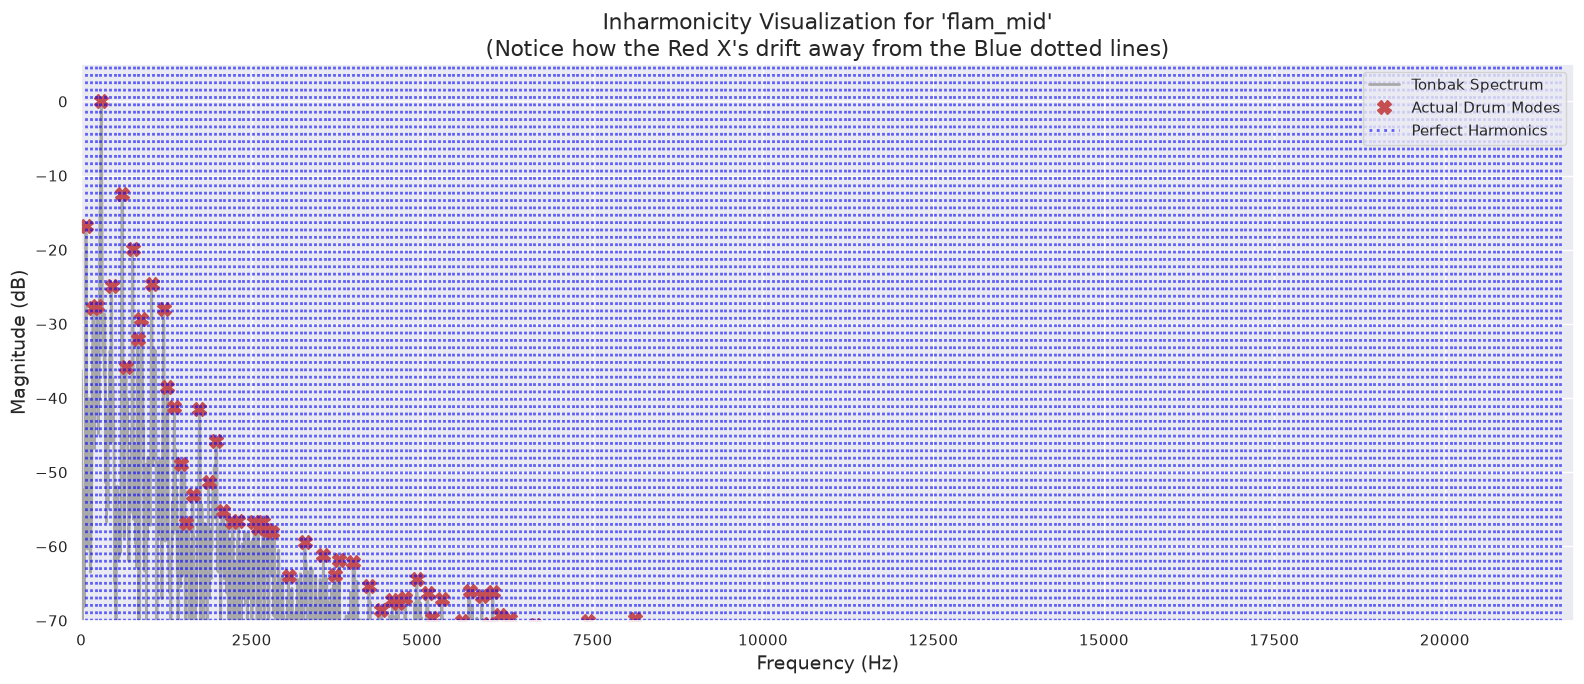

In [4]:
plt.figure(figsize=(16, 7))
plt.plot(freqs, psd_db, color='darkgray', linewidth=2, label="Tonbak Spectrum")

# Plot the Actual Peaks (Red X)
plt.plot(freqs[sorted_peak_indices], psd_db[sorted_peak_indices], "rX", markersize=10, label="Actual Drum Modes")

# Plot the Perfect Harmonic Grid (Blue dotted lines)
max_harmonic = int(freqs[sorted_peak_indices[-1]] / f0) + 1
for n in range(1, max_harmonic):
    plt.axvline(n * f0, color='blue', linestyle=':', alpha=0.6, linewidth=2, 
                label="Perfect Harmonics" if n == 1 else "")

plt.title(f"Inharmonicity Visualization for '{TARGET_STROKE}'\n(Notice how the Red X's drift away from the Blue dotted lines)", fontsize=16)
plt.xlabel("Frequency (Hz)", fontsize=14)
plt.ylabel("Magnitude (dB)", fontsize=14)

# Zoom in on the relevant frequencies
plt.xlim(0, f0 * (max_harmonic - 1) + 200)
plt.ylim(-70, 5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()